In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os, glob, random, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score, classification_report
import tensorflow as tf
from tensorflow.keras import layers, models

DATA_DIR = "/content/drive/MyDrive/XPQRS"
OUTPUT_DIR = "/content/drive/MyDrive/XPQRS/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42
TEST_SIZE = 0.20
FOLDS = 3               # 3 = comparable with the earlier ablation; use 5 for the final confirmation
EPOCHS = 40
RUN_FINAL_TEST = False  # True only when you are ready to test the best kernel on the locked 20%

COMPOUND_CLASSES = {
    "Flicker_with_Sag", "Flicker_with_Swell", "Harmonics_with_Sag",
    "Harmonics_with_Swell", "Sag_with_Harmonics", "Sag_with_Oscillatory_Transient",
    "Swell_with_Harmonics", "Swell_with_Oscillatory_Transient",
}

def set_seed(s=RANDOM_STATE):
    np.random.seed(s); random.seed(s); tf.random.set_seed(s)
set_seed()

In [5]:
signals, labels = [], []
for path in sorted(glob.glob(os.path.join(DATA_DIR, "*.csv"))):
    label = os.path.splitext(os.path.basename(path))[0]
    data = pd.read_csv(path, header=None)
    signals.append(data.values.astype(np.float32))
    labels.extend([label] * len(data))

X_raw = np.vstack(signals)
y = np.array(labels)
classes = sorted(np.unique(y))
y_enc = LabelEncoder().fit(classes).transform(y)
is_compound = np.array([c in COMPOUND_CLASSES for c in classes])
N_SAMPLES = X_raw.shape[1]
X_all = X_raw.reshape(-1, N_SAMPLES, 1)

tv_path, te_path = f"{OUTPUT_DIR}/trainval_idx.npy", f"{OUTPUT_DIR}/test_idx.npy"
if os.path.exists(tv_path) and os.path.exists(te_path):
    trainval_idx, test_idx = np.load(tv_path), np.load(te_path)
    print("Loaded saved split")
else:
    trainval_idx, test_idx = train_test_split(np.arange(len(y)), test_size=TEST_SIZE,
                                              random_state=RANDOM_STATE, stratify=y)
    print("Recreated the same 80/20 split")
print(f"Pool: {len(trainval_idx)} signals | locked test set: {len(test_idx)} (not used in this search)")

Recreated the same 80/20 split
Pool: 13600 signals | locked test set: 3400 (not used in this search)


In [6]:
def build_model(n_classes, n_samples, kernel_sizes=(5, 5, 3), filters=(32, 64, 128)):
    """Base model. Only kernel_sizes is varied in this notebook."""
    x_in = layers.Input(shape=(n_samples, 1))
    x = x_in
    for i in range(3):
        x = layers.Conv1D(filters[i], kernel_size=kernel_sizes[i], activation="relu", padding="same")(x)
        x = layers.BatchNormalization()(x)
        if i < 2:
            x = layers.MaxPooling1D(pool_size=2)(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    m = models.Model(x_in, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def make_callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
    ]

def evaluate_kernels(kernel_sizes, n_folds=FOLDS):
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=RANDOM_STATE)
    accs, f1s, n_params = [], [], None
    for tr, va in skf.split(trainval_idx, y[trainval_idx]):
        tr_idx, va_idx = trainval_idx[tr], trainval_idx[va]
        fit_idx, es_idx = train_test_split(tr_idx, test_size=0.15, random_state=RANDOM_STATE,
                                           stratify=y[tr_idx])
        tf.keras.backend.clear_session(); set_seed()
        m = build_model(len(classes), N_SAMPLES, kernel_sizes=kernel_sizes)
        n_params = m.count_params()
        m.fit(X_all[fit_idx], y_enc[fit_idx], validation_data=(X_all[es_idx], y_enc[es_idx]),
              epochs=EPOCHS, batch_size=32, callbacks=make_callbacks(), verbose=0)
        pred = np.argmax(m.predict(X_all[va_idx], verbose=0), axis=1)
        accs.append(accuracy_score(y_enc[va_idx], pred) * 100)
        f1s.append(f1_score(y_enc[va_idx], pred, labels=range(len(classes)), average=None, zero_division=0))
    return np.array(accs), np.array(f1s).mean(axis=0), n_params

In [7]:
KERNELS = {
    "K5-5-3 (baseline)": (5, 5, 3),
    "K3-3-3":            (3, 3, 3),
    "K5-3-3":            (5, 3, 3),
    "K5-5-5":            (5, 5, 5),
    "K7-5-3":            (7, 5, 3),
    "K3-5-7":            (3, 5, 7),
    "K7-7-7":            (7, 7, 7),
    "K9-7-5":            (9, 7, 5),
}
print(len(KERNELS), "kernel settings x", FOLDS, "folds =", len(KERNELS) * FOLDS, "training runs")

8 kernel settings x 3 folds = 24 training runs


In [8]:
rows = []
for name, ks in KERNELS.items():
    t0 = time.time()
    accs, mf1, n_params = evaluate_kernels(ks)
    rows.append({"kernel": name, "val_acc_mean": accs.mean(), "val_acc_std": accs.std(),
                 "compound_f1": mf1[is_compound].mean(), "non_compound_f1": mf1[~is_compound].mean(),
                 "n_params": n_params, **{f"fold{i+1}": a for i, a in enumerate(accs)}})
    print(f"{name:<20} {accs.mean():6.2f}% +/- {accs.std():.2f}  params {n_params:>7,}  ({time.time()-t0:.0f}s)")
    pd.DataFrame(rows).to_csv(f"{OUTPUT_DIR}/kernel_search_results.csv", index=False)   # saved as it goes

K5-5-3 (baseline)     93.95% +/- 0.50  params  45,457  (175s)
K3-3-3                95.48% +/- 0.23  params  41,297  (176s)
K5-3-3                93.57% +/- 0.47  params  41,361  (170s)
K5-5-5                94.88% +/- 0.77  params  61,841  (175s)
K7-5-3                94.98% +/- 0.36  params  45,521  (173s)
K3-5-7                94.50% +/- 0.45  params  78,161  (177s)
K7-7-7                94.71% +/- 0.08  params  82,385  (177s)
K9-7-5                95.19% +/- 0.33  params  66,065  (179s)


In [9]:
res = pd.DataFrame(rows)
base = res.loc[res.kernel == "K5-5-3 (baseline)", "val_acc_mean"].iloc[0]
res["change_vs_baseline"] = res["val_acc_mean"] - base
res = res.sort_values("val_acc_mean", ascending=False).reset_index(drop=True)
res.to_csv(f"{OUTPUT_DIR}/kernel_search_results.csv", index=False)
best_kernel_name = res.loc[0, "kernel"]
print(f"Baseline validation accuracy: {base:.2f}%")
print(f"BEST KERNEL: {best_kernel_name}  ->  {res.loc[0,'val_acc_mean']:.2f}% +/- {res.loc[0,'val_acc_std']:.2f}\n")
print(res[["kernel", "val_acc_mean", "val_acc_std", "change_vs_baseline", "compound_f1", "n_params"]].round(3).to_string(index=False))

Baseline validation accuracy: 93.95%
BEST KERNEL: K3-3-3  ->  95.48% +/- 0.23

           kernel  val_acc_mean  val_acc_std  change_vs_baseline  compound_f1  n_params
           K3-3-3        95.478        0.234               1.529        0.943     41297
           K9-7-5        95.191        0.334               1.243        0.951     66065
           K7-5-3        94.978        0.365               1.029        0.948     45521
           K5-5-5        94.882        0.767               0.934        0.941     61841
           K7-7-7        94.706        0.082               0.757        0.941     82385
           K3-5-7        94.500        0.453               0.552        0.942     78161
K5-5-3 (baseline)        93.949        0.500               0.000        0.932     45457
           K5-3-3        93.566        0.468              -0.382        0.930     41361


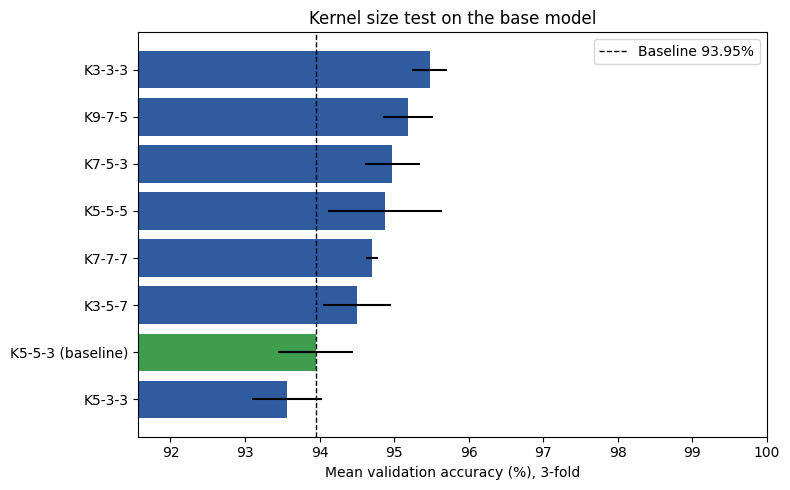

In [10]:
plot_df = res.sort_values("val_acc_mean")
cols = ["#3F9E4D" if "baseline" in k else "#2F5C9E" for k in plot_df["kernel"]]
plt.figure(figsize=(8, 5))
plt.barh(plot_df["kernel"], plot_df["val_acc_mean"], xerr=plot_df["val_acc_std"], color=cols)
plt.axvline(base, color="k", linestyle="--", linewidth=1, label=f"Baseline {base:.2f}%")
plt.xlim(max(0, plot_df["val_acc_mean"].min() - 2), 100)
plt.xlabel(f"Mean validation accuracy (%), {FOLDS}-fold"); plt.legend()
plt.title("Kernel size test on the base model")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/kernel_search.png", dpi=150); plt.show()

In [11]:
if RUN_FINAL_TEST:
    ks = KERNELS[best_kernel_name]
    fit_idx, es_idx = train_test_split(trainval_idx, test_size=0.15, random_state=RANDOM_STATE,
                                       stratify=y[trainval_idx])
    tf.keras.backend.clear_session(); set_seed()
    model = build_model(len(classes), N_SAMPLES, kernel_sizes=ks)
    model.fit(X_all[fit_idx], y_enc[fit_idx], validation_data=(X_all[es_idx], y_enc[es_idx]),
              epochs=EPOCHS, batch_size=32, callbacks=make_callbacks(), verbose=0)
    model.save(f"{OUTPUT_DIR}/best_kernel_cnn.keras")
    pred = np.argmax(model.predict(X_all[test_idx], verbose=0), axis=1)
    print(f"Kernel {best_kernel_name}: TEST ACCURACY (unseen 20%) = {accuracy_score(y_enc[test_idx], pred)*100:.2f}%")
    print(classification_report(y_enc[test_idx], pred, target_names=classes, digits=4, zero_division=0))
else:
    print("RUN_FINAL_TEST is False, so the locked test set has not been touched.")

RUN_FINAL_TEST is False, so the locked test set has not been touched.
